# Volume 2, Appendix G: Positive Matrices (Python companion)

Exercises first, solutions at the end. We watch a positive matrix squeeze the positive cone, measure the speed of the power method, detect periods and see the regular polygon of peripheral eigenvalues, find the worst primitive matrices by brute force, rank web pages, and let a population settle into its stable age distribution. We use `numpy`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import itertools, math
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(7)

## Exercises

**P7.1 (★) Perron in action.** For a random positive $6\times6$ matrix, compute $\rho$, the Perron vector and the moduli of the other eigenvalues (Theorem 7.1). Check the Collatz–Wielandt bounds $\min_i(Ax)_i/x_i\le\rho\le\max_i(Ax)_i/x_i$ for random positive $x$ (Exercise 7.3), and plot how the oscillation of $A^kx/z$ shrinks (Lemma 7.2).

**P7.2 (★) The speed of the power method.** For positive matrices with various ratios $|\lambda_2|/\rho$, run the power method and plot the error against the iteration number on a log scale. Compare the slope with $\log(|\lambda_2|/\rho)$ and with the bound $1-c^2$ of Lemma 7.2.

**P7.3 (★★) Periods and polygons.** Write a function computing the period of a strongly connected digraph from the levels of Proposition 7.6 (breadth-first search, then the gcd of $\ell(i)+1-\ell(j)$ over edges $i\to j$). Apply it to the digraph of Figure 7.1 and to random graphs of period $4$, and plot the eigenvalues in the complex plane together with the circle of radius $\rho$ (Theorem 7.5).

**P7.4 (★★) The exponent of a primitive matrix.** The *exponent* of a primitive $A$ is the least $k$ with $A^k>0$. Compute it for all $0/1$ matrices of size $n\le4$ and list the values that occur; compare the maximum with $(n-1)^2+1$ (Theorem 7.8). Which values below the maximum never occur? Then check the Wielandt matrix for $n\le10$ (Exercise 7.12).

**P7.5 (★★) PageRank.** Recompute the PageRank of Figure 7.2 by the power method, compare with the ranking by number of incoming links, and study how the ranking changes with $\alpha\in\{0.5,0.85,0.99\}$. Then build a random web with $2000$ pages by preferential attachment and check that the power method needs at most about $\log(10^{-8})/\log\alpha$ iterations to reach accuracy $10^{-8}$ (Exercise 7.9).

**P7.6 (★) A population settles down.** Take a Leslie matrix with five age classes, simulate $40$ generations from a population of newborns only, and plot the age distribution converging to the Perron vector (Example 7.11). Compare the growth factor with the root of the Euler–Lotka equation. Finally run Fibonacci's rabbits from one adult pair and watch the juvenile fraction approach $1/\varphi^2$.

## Solutions

### P7.1
**How to find it.** `numpy.linalg.eig` gives everything; sort eigenvalues by modulus. For the oscillation, divide $A^kx$ by $z$ coordinatewise.

rho = 3.177902   Perron vector = [0.2064 0.1546 0.1945 0.1598 0.17   0.1147]
other |lambda| = [0.679  0.5777 0.5777 0.5539 0.1284]
  0.8228 <= rho <= 88.8370
  1.7692 <= rho <= 19.4201
  1.7938 <= rho <= 23.0093
  1.9543 <= rho <= 10.0235
  2.3214 <= rho <= 10.1027


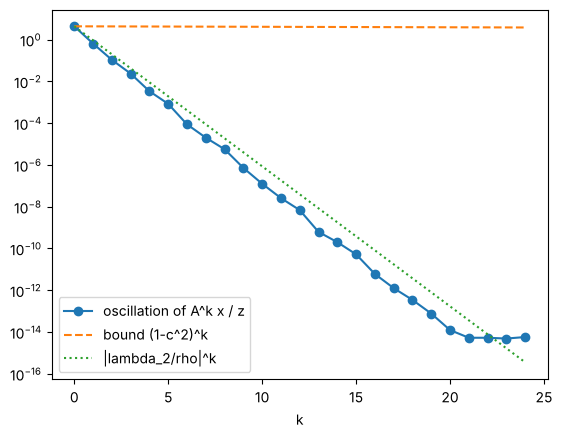

In [2]:
A = rng.random((6, 6)) + 0.05
ev, V = np.linalg.eig(A)
order = np.argsort(-np.abs(ev)); ev, V = ev[order], V[:, order]
rho = ev[0].real; z = np.abs(V[:, 0].real); z /= z.sum()
print("rho =", round(rho, 6), "  Perron vector =", z.round(4))
print("other |lambda| =", np.abs(ev[1:]).round(4))
for _ in range(5):
    x = rng.random(6) + 0.01
    q = A @ x / x
    print(f"  {q.min():.4f} <= rho <= {q.max():.4f}")
x = rng.random(6) + 0.01; osc = []
for k in range(25):
    r = x / z; osc.append(r.max() - r.min()); x = A @ x / rho
c = min(A[i, j] / A[k, j] for i in range(6) for j in range(6) for k in range(6))
plt.semilogy(osc, 'o-', label='oscillation of A^k x / z')
plt.semilogy(osc[0] * (1 - c**2) ** np.arange(25), '--', label='bound (1-c^2)^k')
plt.semilogy(osc[0] * (abs(ev[1]) / rho) ** np.arange(25), ':', label='|lambda_2/rho|^k')
plt.legend(); plt.xlabel("k"); plt.show()

The bound $1-c^2$ is honest but pessimistic; the true rate is $|\lambda_2|/\rho$.

### P7.2
**How to find it.** A positive matrix with $|\lambda_2|$ close to $\rho$ is one that almost splits into two blocks: take two groups of states with weights $1$ inside each group and a small $\delta$ between groups (plus a little noise). For $\delta\to0$ it becomes reducible and $|\lambda_2|/\rho\to1$. Measure the slope only while the error is well above machine precision.

delta=  0.5: observed rate 0.3190, |lambda_2|/rho = 0.3190
delta=  0.2: observed rate 0.6443, |lambda_2|/rho = 0.6443
delta= 0.05: observed rate 0.8628, |lambda_2|/rho = 0.8628
delta= 0.01: observed rate 0.9289, |lambda_2|/rho = 0.9289


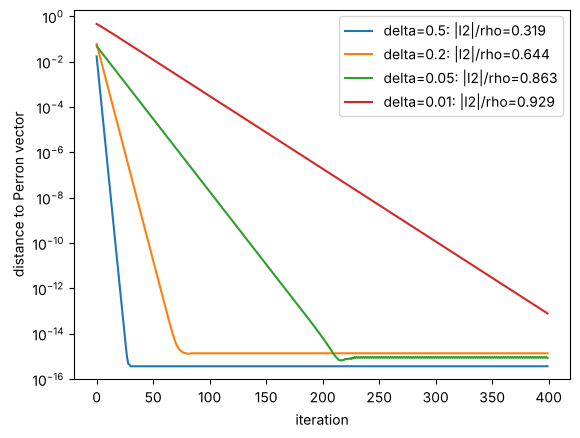

In [3]:
n = 8
for delta in (0.5, 0.2, 0.05, 0.01):
    A = np.full((n, n), delta); A[:4, :4] = A[4:, 4:] = 1; A = A + 0.05 * rng.random((n, n))
    ev, V = np.linalg.eig(A); order = np.argsort(-np.abs(ev)); ev, V = ev[order], V[:, order]
    z = np.abs(V[:, 0].real); z /= np.linalg.norm(z); ratio = abs(ev[1]) / ev[0].real
    x = rng.random(n); errs = []
    for k in range(400):
        x = A @ x; x /= np.linalg.norm(x); errs.append(np.linalg.norm(x - z))
    good = [k for k, e in enumerate(errs) if e > 1e-12]
    k0, k1 = good[len(good) // 4], good[-1]
    rate = math.exp((math.log(errs[k1]) - math.log(errs[k0])) / (k1 - k0))
    plt.semilogy(errs, label=f"delta={delta}: |l2|/rho={ratio:.3f}")
    print(f"delta={delta:5}: observed rate {rate:.4f}, |lambda_2|/rho = {ratio:.4f}")
plt.ylim(1e-16, 2); plt.legend(); plt.xlabel("iteration"); plt.ylabel("distance to Perron vector"); plt.show()

### P7.3
**How to find it.** BFS from vertex $0$ gives distances $\ell$; for every edge $i\to j$, the quantity $\ell(i)+1-\ell(j)$ is a difference of two walk lengths to $j$, hence a multiple of $h$, and the gcd of these numbers is exactly $h$ (they include the lengths of enough closed walks).

Figure graph : period 3   peripheral eigenvalues: [-0.8132+1.4086j -0.8132-1.4086j  1.6265+0.j    ]
random, period 4 : period 4   peripheral eigenvalues: [-2.0819+0.j      0.    +2.0819j  0.    -2.0819j  2.0819+0.j    ]


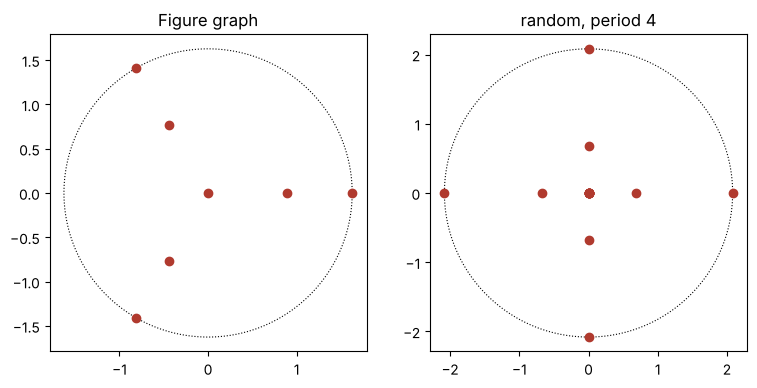

In [4]:
def period(A):
    n = len(A); dist = [-1] * n; dist[0] = 0; dq = deque([0])
    while dq:
        i = dq.popleft()
        for j in range(n):
            if A[i][j] and dist[j] < 0:
                dist[j] = dist[i] + 1; dq.append(j)
    assert min(dist) >= 0, "not strongly connected from vertex 0"
    g = 0
    for i in range(n):
        for j in range(n):
            if A[i][j]: g = math.gcd(g, dist[i] + 1 - dist[j])
    return g

E = [(1, 3), (1, 4), (2, 4), (2, 5), (3, 6), (4, 6), (4, 7), (5, 7), (6, 1), (6, 2), (7, 2)]
A7 = np.zeros((7, 7))
for a, b in E: A7[a - 1, b - 1] = 1
def random_periodic(h, size, p=0.5):
    cls = [list(range(k * size, (k + 1) * size)) for k in range(h)]
    A = np.zeros((h * size, h * size))
    while True:
        for k in range(h):
            for i in cls[k]:
                for j in cls[(k + 1) % h]:
                    A[i, j] = rng.random() < p
        if (np.linalg.matrix_power(np.eye(h * size) + A, h * size - 1) > 0).all(): return A
A4 = random_periodic(4, 4)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, (name, A) in zip(axes, [("Figure graph", A7), ("random, period 4", A4)]):
    ev = np.linalg.eigvals(A); rho = max(abs(ev))
    print(name, ": period", period(A), "  peripheral eigenvalues:", np.round(ev[np.isclose(abs(ev), rho)], 4))
    t = np.linspace(0, 2 * np.pi, 200)
    ax.plot(rho * np.cos(t), rho * np.sin(t), 'k:', lw=0.8); ax.plot(ev.real, ev.imag, 'o', color='#b03a2e')
    ax.set_aspect('equal'); ax.set_title(name)
plt.show()

For period $4$ the whole spectrum is invariant under multiplication by $i$: the picture has the symmetry of a square, as Theorem 7.5 predicts.

### P7.4
**How to find it.** Encode each $0/1$ matrix as an integer; for each, compute powers with boolean arithmetic until all entries are positive or until the bound $(n-1)^2+1$ is exceeded (then it is not primitive: by Wielandt, a primitive matrix is positive by then). For $n=4$ there are $65536$ matrices; vectorising over all of them at once keeps it fast.

In [5]:
def exponents(n):
    N = 2 ** (n * n)
    mats = ((np.arange(N)[:, None] >> np.arange(n * n)) & 1).reshape(N, n, n).astype(np.int64)
    P = mats.copy(); exp = np.zeros(N, dtype=int); bound = (n - 1) ** 2 + 1
    for k in range(1, bound + 1):
        pos = (P > 0).all(axis=(1, 2)) & (exp == 0)
        exp[pos] = k
        P = (np.einsum('aij,ajk->aik', P, mats) > 0).astype(np.int64)
    return exp

for n in range(2, 5):
    e = exponents(n); vals = sorted(set(e[e > 0]))
    gaps = [k for k in range(1, (n - 1) ** 2 + 2) if k not in vals]
    print(f"n={n}: exponents occurring {vals}; max {max(vals)} = (n-1)^2+1 = {(n-1)**2+1}; never: {gaps}")

for n in range(3, 11):
    W = np.zeros((n, n), dtype=np.int64)
    for i in range(n - 1): W[i, i + 1] = 1
    W[n - 1, 0] = W[n - 1, 1] = 1
    P = np.eye(n, dtype=np.int64); k = 0
    while not (P > 0).all():
        P = ((P @ W) > 0).astype(np.int64); k += 1
    print(f"Wielandt matrix n={n}: exponent {k}, (n-1)^2+1 = {(n-1)**2+1}")

n=2: exponents occurring [np.int64(1), np.int64(2)]; max 2 = (n-1)^2+1 = 2; never: []
n=3: exponents occurring [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]; max 5 = (n-1)^2+1 = 5; never: []


n=4: exponents occurring [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(9), np.int64(10)]; max 10 = (n-1)^2+1 = 10; never: [7, 8]
Wielandt matrix n=3: exponent 5, (n-1)^2+1 = 5
Wielandt matrix n=4: exponent 10, (n-1)^2+1 = 10
Wielandt matrix n=5: exponent 17, (n-1)^2+1 = 17
Wielandt matrix n=6: exponent 26, (n-1)^2+1 = 26
Wielandt matrix n=7: exponent 37, (n-1)^2+1 = 37
Wielandt matrix n=8: exponent 50, (n-1)^2+1 = 50
Wielandt matrix n=9: exponent 65, (n-1)^2+1 = 65
Wielandt matrix n=10: exponent 82, (n-1)^2+1 = 82


Not every value below the maximum occurs: for $n=4$ the exponents $7$ and $8$ are impossible, although $9$ and $10$ occur. Dulmage and Mendelsohn (1964) discovered these *gaps* in the exponent set, which grow with $n$.

### P7.5
**How to find it.** Build the stochastic matrix row by row, mix with the uniform matrix, and iterate $\pi\mapsto\pi G$. For the large web, never form $G$: $\pi G=\alpha\pi P+(1-\alpha)/n$ uses only the sparse links.

In [6]:
names = "ABCDEFGH"
links = {"A": "BC", "B": "C", "C": "A", "D": "CA", "E": "DBF", "F": "CE", "G": "CF", "H": "GC"}
n = 8; P = np.zeros((n, n))
for v, outs in links.items():
    for w in outs: P[names.index(v), names.index(w)] = 1 / len(outs)
indeg = P.astype(bool).sum(axis=0)
for alpha in (0.5, 0.85, 0.99):
    G = alpha * P + (1 - alpha) / n; pi = np.ones(n) / n
    for _ in range(2000): pi = pi @ G
    rank = "".join(names[i] for i in np.argsort(-pi))
    print(f"alpha={alpha}: ranking {rank}  PageRank {dict(zip(names, pi.round(3)))}")
print("in-degree ranking:", "".join(names[i] for i in np.argsort(-indeg, kind='stable')), dict(zip(names, indeg)))

N, alpha = 2000, 0.85
targets = [[]]
deg = np.ones(1)
for v in range(1, N):                                     # preferential attachment: link to popular pages
    k = min(v, 3)
    outs = rng.choice(v, size=k, replace=False, p=deg[:v] / deg[:v].sum())
    targets.append(list(outs)); deg = np.append(deg, 1.0); deg[outs] += 1
def step(pi):
    new = np.full(N, (1 - alpha) / N)
    dangling = sum(pi[v] for v in range(N) if not targets[v])
    new += alpha * dangling / N
    for v in range(N):
        for w in targets[v]: new[w] += alpha * pi[v] / len(targets[v])
    return new
pi = np.ones(N) / N; it = 0
while True:
    new = step(pi); it += 1
    if np.abs(new - pi).sum() < 1e-8: break
    pi = new
print(f"large web: converged in {it} iterations; worst-case bound log(1e-8)/log(alpha) = {math.log(1e-8) / math.log(alpha):.0f}")

alpha=0.5: ranking CABFEGDH  PageRank {'A': np.float64(0.211), 'B': np.float64(0.13), 'C': np.float64(0.259), 'D': np.float64(0.077), 'E': np.float64(0.087), 'F': np.float64(0.096), 'G': np.float64(0.078), 'H': np.float64(0.062)}
alpha=0.85: ranking CABFEDGH  PageRank {'A': np.float64(0.329), 'B': np.float64(0.169), 'C': np.float64(0.351), 'D': np.float64(0.029), 'E': np.float64(0.036), 'F': np.float64(0.04), 'G': np.float64(0.027), 'H': np.float64(0.019)}
alpha=0.99: ranking CABFEDGH  PageRank {'A': np.float64(0.395), 'B': np.float64(0.198), 'C': np.float64(0.396), 'D': np.float64(0.002), 'E': np.float64(0.003), 'F': np.float64(0.003), 'G': np.float64(0.002), 'H': np.float64(0.001)}
in-degree ranking: CABFDEGH {'A': np.int64(2), 'B': np.int64(2), 'C': np.int64(6), 'D': np.int64(1), 'E': np.int64(1), 'F': np.int64(2), 'G': np.int64(1), 'H': np.int64(0)}
large web: converged in 31 iterations; worst-case bound log(1e-8)/log(alpha) = 113


### P7.6
**How to find it.** Iterate $x_{k+1}=Lx_k$ and normalise; the Euler–Lotka root is the positive root of $\sum_if_i\ell_i\lambda^{-i}=1$, found by bisection since the left side decreases.

Euler-Lotka root 1.133335, rho(L) = 1.133335, net reproductive rate 1.442


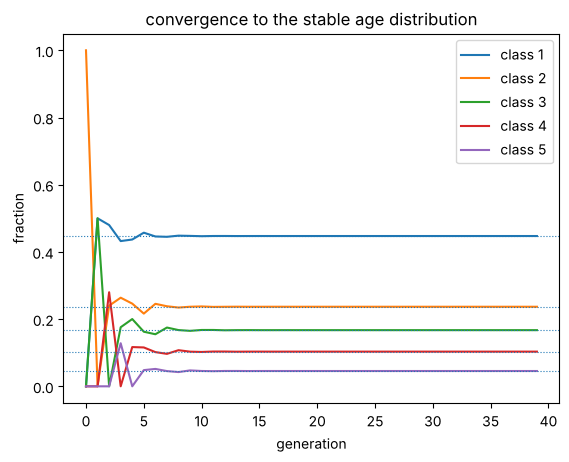

Fibonacci after 15 months (juvenile, adult) pairs: [610 987]  juvenile fraction 0.381966  1/phi^2 = 0.381966


In [7]:
f = np.array([0.0, 0.8, 1.2, 1.0, 0.3]); s = np.array([0.6, 0.8, 0.7, 0.5])
n = len(f); L = np.zeros((n, n)); L[0] = f; L[np.arange(1, n), np.arange(n - 1)] = s
ell = np.concatenate([[1], np.cumprod(s)])
g = lambda lam: np.sum(f * ell / lam ** np.arange(1, n + 1))
lo, hi = 1e-6, 10.0
for _ in range(200):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if g(mid) > 1 else (lo, mid)
ev = np.linalg.eigvals(L); rho = max(ev.real)
z = ell / lo ** np.arange(n); z /= z.sum()
print(f"Euler-Lotka root {lo:.6f}, rho(L) = {rho:.6f}, net reproductive rate {np.sum(f * ell):.3f}")
x = np.array([1.0, 0, 0, 0, 0]); hist = []
for k in range(40):
    x = L @ x; hist.append(x / x.sum())
hist = np.array(hist)
for i in range(n): plt.plot(hist[:, i], label=f"class {i+1}")
plt.gca().set_prop_cycle(None)
for i in range(n): plt.axhline(z[i], ls=':', lw=0.8)
plt.legend(); plt.xlabel("generation"); plt.ylabel("fraction"); plt.title("convergence to the stable age distribution"); plt.show()

F = np.array([[0, 1], [1, 1]]); v = np.array([0, 1])
for k in range(1, 16):
    v = F @ v
print("Fibonacci after 15 months (juvenile, adult) pairs:", v, " juvenile fraction", round(v[0] / v.sum(), 6),
      " 1/phi^2 =", round(2 / (3 + math.sqrt(5)), 6))